In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Коренева директорія проєкту
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw_path = root / "data" / "raw"

# Зчитування файлів
customers = pd.read_csv(raw_path / "customers.csv")
merchants = pd.read_csv(raw_path / "merchants.csv")
products = pd.read_csv(raw_path / "products.csv")
orders = pd.read_csv(raw_path / "orders.csv")

# Базовий огляд замовлень
display(orders.head(3))
orders.info()

,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
0,S02-O0000001,S02-C000523,S02-M00029,2025-09-01T10:07:16Z,delivered,UAH,648.75,67.22,0.00,715.97
1,S02-O0000002,S02-C000067,S02-M00027,2025-09-01T10:42:25Z,delivered,UAH,114.31,78.37,11.43,181.25
2,S02-O0000003,S02-C000520,S02-M00015,2025-09-01T12:31:06Z,delivered,UAH,152.65,66.18,0.00,218.83


<class 'pandas.DataFrame'>
RangeIndex: 6001 entries, 0 to 6000
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         6001 non-null   str    
 1   customer_id      6001 non-null   str    
 2   merchant_id      6001 non-null   str    
 3   created_at       6001 non-null   str    
 4   order_status     6001 non-null   str    
 5   currency         6001 non-null   str    
 6   subtotal_amount  6001 non-null   float64
 7   delivery_fee     6001 non-null   float64
 8   discount_amount  6001 non-null   float64
 9   total_amount     6001 non-null   float64
dtypes: float64(4), str(6)
memory usage: 469.0 KB


In [2]:
dfs = {
    "customers": (customers, "customer_id", "registered_at"),
    "merchants": (merchants, "merchant_id", "opened_at"),
    "products": (products, "product_id", "updated_at"),
    "orders": (orders, "order_id", "created_at"),
}

summary_list = []
for name, (df, pk, date_col) in dfs.items():
  parsed_dates = pd.to_datetime(df[date_col], errors="coerce")
  summary_list.append({
      "Джерело": name,
      "Кількість рядків": len(df),
      "Кількість колонок": df.shape[1],
      "Унікальних PK": df[pk].nunique(),
      "Повних дублікатів": df.duplicated().sum(),
      "Рядків із NaN": df.isnull().any(axis=1).sum(),
      "Мін. дата": str(parsed_dates.min()),
      "Макс. дата": str(parsed_dates.max()),
  })

summary_table = pd.DataFrame(summary_list)
display(summary_table)


,Джерело,Кількість рядків,Кількість колонок,Унікальних PK,Повних дублікатів,Рядків із NaN,Мін. дата,Макс. дата
0,customers,801,8,800,1,5,2024-03-11 06:42:50.308542928+00:00,2026-08-29 21:45:52.142607403+00:00
1,merchants,43,7,42,1,0,2019-09-10 15:47:58.509758852+00:00,2025-06-18 05:53:38.810918893+00:00
2,products,502,7,501,1,0,2025-08-02 21:14:28.725558475+00:00,2026-08-30 13:28:46.712938780+00:00
3,orders,6001,10,6000,1,0,2025-09-01 10:07:16+00:00,2026-08-31 20:36:13+00:00


In [3]:
# Графік 1: Кількість замовлень за статусами
plt.figure(figsize=(7, 3.5))
status_counts = orders['status'].value_counts(dropna=False)
status_counts.plot(kind='bar', color='cornflowerblue', edgecolor='black')
plt.title('Розподіл замовлень за статусами (orders.status)')
plt.xlabel('Статус')
plt.ylabel('Кількість замовлень')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Графік 2: Динаміка замовлень за датою створення
plt.figure(figsize=(9, 3.5))
orders_created = pd.to_datetime(orders['created_at'], errors='coerce')
orders_by_date = orders_created.dt.date.value_counts().sort_index()
orders_by_date.plot(kind='line', marker='o', color='darkorange', linewidth=1.5)
plt.title('Динаміка замовлень за датами створення')
plt.xlabel('Дата')
plt.ylabel('Кількість замовлень')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


KeyError: 'status'

<Figure size 700x350 with 0 Axes>

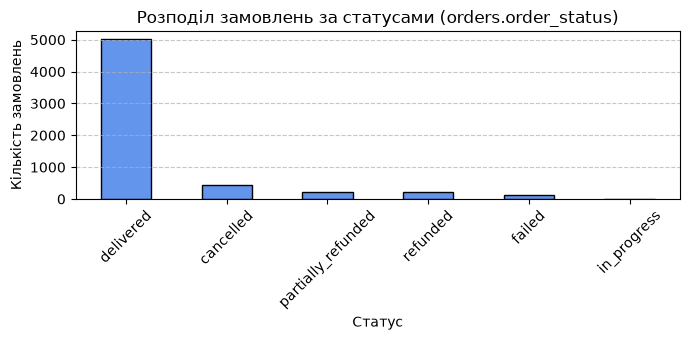

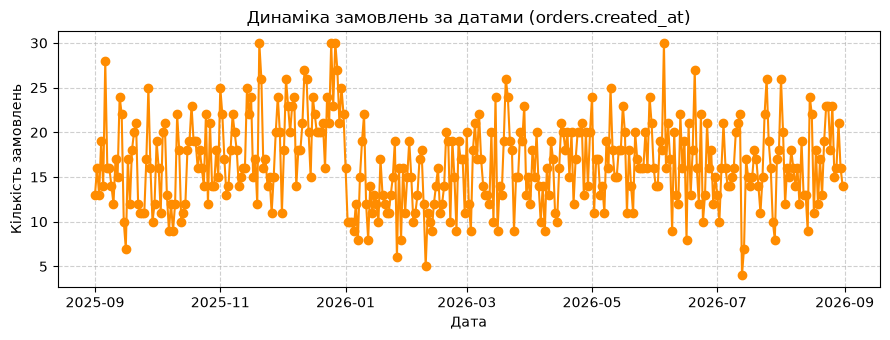

In [4]:
# Пошук правильної назви колонки статусу
status_col = next(
    (c for c in orders.columns if "status" in c.lower()), "status"
)
date_col = next(
    (
        c
        for c in orders.columns
        if any(w in c.lower() for w in ["created", "date", "time"])
    ),
    "created_at",
)

# Графік 1: Кількість замовлень за статусами
plt.figure(figsize=(7, 3.5))
status_counts = orders[status_col].value_counts(dropna=False)
status_counts.plot(kind="bar", color="cornflowerblue", edgecolor="black")
plt.title(f"Розподіл замовлень за статусами (orders.{status_col})")
plt.xlabel("Статус")
plt.ylabel("Кількість замовлень")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# Графік 2: Динаміка замовлень за датою створення
plt.figure(figsize=(9, 3.5))
orders_created = pd.to_datetime(orders[date_col], errors="coerce")
orders_by_date = orders_created.dt.date.value_counts().sort_index()
orders_by_date.plot(kind="line", marker="o", color="darkorange", linewidth=1.5)
plt.title(f"Динаміка замовлень за датами (orders.{date_col})")
plt.xlabel("Дата")
plt.ylabel("Кількість замовлень")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [5]:
# 1. Повторення ключа order_id
dups_pk = orders[orders['order_id'].duplicated(keep=False)]
print(f"1. Рядків із дублікатами ключа order_id: {len(dups_pk)}")
if not dups_pk.empty:
  display(dups_pk[['order_id', 'customer_id', 'total_amount', 'created_at']].head(4))

# 2. Порушення зв'язку: orders -> customers
missing_cust = orders[~orders['customer_id'].isin(customers['customer_id'])]
print(f"\n2. Замовлень із невідомим customer_id: {len(missing_cust)}")
if not missing_cust.empty:
  display(missing_cust[['order_id', 'customer_id', 'total_amount']].head(2))

# 3. Порушення зв'язку: orders -> merchants
missing_merch = orders[~orders['merchant_id'].isin(merchants['merchant_id'])]
print(f"\n3. Замовлень із невідомим merchant_id: {len(missing_merch)}")

# 4. Некоректні/пошкоджені дати
corrupt_dates = (orders['created_at'].notnull() & pd.to_datetime(orders['created_at'], errors='coerce').isnull()).sum()
print(f"\n4. Замовлень із пошкодженим форматом дати: {corrupt_dates}")

# 5. Аномальні суми та коди валют
invalid_amt = (orders['total_amount'] <= 0).sum()
print(f"\n5. Замовлень із total_amount <= 0: {invalid_amt}")
print("\nРозподіл валют (currency):")
print(orders['currency'].value_counts(dropna=False))

1. Рядків із дублікатами ключа order_id: 2


,order_id,customer_id,total_amount,created_at
5866,S02-O0005867,S02-C000097,355.92,2026-08-24T14:21:17Z
6000,S02-O0005867,S02-C000097,355.92,2026-08-24T14:21:17Z



2. Замовлень із невідомим customer_id: 1


,order_id,customer_id,total_amount
4192,S02-O0004193,S02-C999999,404.79



3. Замовлень із невідомим merchant_id: 1

4. Замовлень із пошкодженим форматом дати: 2

5. Замовлень із total_amount <= 0: 0

Розподіл валют (currency):
currency
UAH     5926
USD       48
EUR       26
UA H       1
Name: count, dtype: int64
